# Lecture 5 — Class Exercise
## Distribution Charts: Airbnb London

> **Push to:** `week05/lecture05_exercise.ipynb`

**Rules:**
1. Cap price outliers at 95th percentile — annotate this
2. Every chart has a **median/mean reference line** with annotation
3. Insight title names the distribution shape or key finding
4. Colour has meaning — don't use colour just for decoration

---


In [2]:
import pandas as pd

df = pd.read_csv('airbnb_london.csv')

df.head()

,neighbourhood,room_type,price,minimum_nights,number_of_reviews,availability_365,reviews_per_month
0,Hammersmith,Entire home/apt,148.55,6,158,302,3.75
1,Kensington and Chelsea,Private room,393.56,29,46,323,2.56
2,Camden,Entire home/apt,197.64,19,242,291,2.52
3,Southwark,Private room,70.47,6,199,22,1.24
4,Hammersmith,Private room,96.58,18,110,103,4.11


In [3]:
import os

print("Current folder:", os.getcwd())
print("Files in this folder:", os.listdir())

Current folder: C:\Users\Sunny\DV_Exercises
Files in this folder: ['.ipynb_checkpoints', 'airbnb_london.csv', 'co2_emissions.csv', 'gapminder.csv', 'lecture03_exercise.ipynb', 'lecture04_eexercise.ipynb', 'lecture05_exercise.ipynb', 'Untitled.ipynb']


In [7]:
import pandas as pd
import plotly.express as px
import numpy as np

# Dataset: Airbnb London Listings
df = pd.read_csv('airbnb_london.csv')

print(f"Loaded: {len(df)} listings")
print(df.describe().round(1))

df.head()

Loaded: 2500 listings
        price  minimum_nights  number_of_reviews  availability_365  \
count  2500.0          2500.0             2500.0            2500.0   
mean    148.6            14.8              147.9             183.7   
std     110.9             8.4               86.3             105.5   
min      20.5             1.0                0.0               0.0   
25%      71.7             8.0               74.0              92.0   
50%     117.5            15.0              145.0             182.0   
75%     188.9            22.0              222.2             277.0   
max    1032.4            29.0              299.0             364.0   

       reviews_per_month  
count             2500.0  
mean                 2.0  
std                  2.0  
min                  0.0  
25%                  0.6  
50%                  1.4  
75%                  2.8  
max                 15.2  


,neighbourhood,room_type,price,minimum_nights,number_of_reviews,availability_365,reviews_per_month
0,Hammersmith,Entire home/apt,148.55,6,158,302,3.75
1,Kensington and Chelsea,Private room,393.56,29,46,323,2.56
2,Camden,Entire home/apt,197.64,19,242,291,2.52
3,Southwark,Private room,70.47,6,199,22,1.24
4,Hammersmith,Private room,96.58,18,110,103,4.11


In [8]:
p95 = df['price'].quantile(0.95)
df_cap = df[df['price'] <= p95]
print(f"95th percentile price: £{p95:.0f}")
print(df_cap.groupby('room_type')['price'].describe().round(1))


95th percentile price: £373
                  count   mean   std   min    25%    50%    75%    max
room_type                                                             
Entire home/apt  1251.0  176.3  75.7  28.0  119.6  163.4  223.5  372.6
Private room      942.0   87.3  39.5  20.9   59.0   78.6  106.0  277.9
Shared room       182.0   46.3  14.1  20.5   36.8   44.1   54.3   92.8


## Task 1 — Histogram: price by room type (overlapping distributions)

**What to build:** A histogram showing price distributions for **Entire home/apt vs Private room** (exclude Shared room — too few observations) overlaid on the same chart.

**Requirements:**
- Both room types on the same chart (use `color='room_type'`)
- `barmode='overlay'` with `opacity=0.6` so both distributions are visible
- A vertical line for the median of EACH room type, differently coloured
- Insight title comparing the two distributions

> 💡 `df_cap[df_cap['room_type'].isin(['Entire home/apt','Private room'])]`


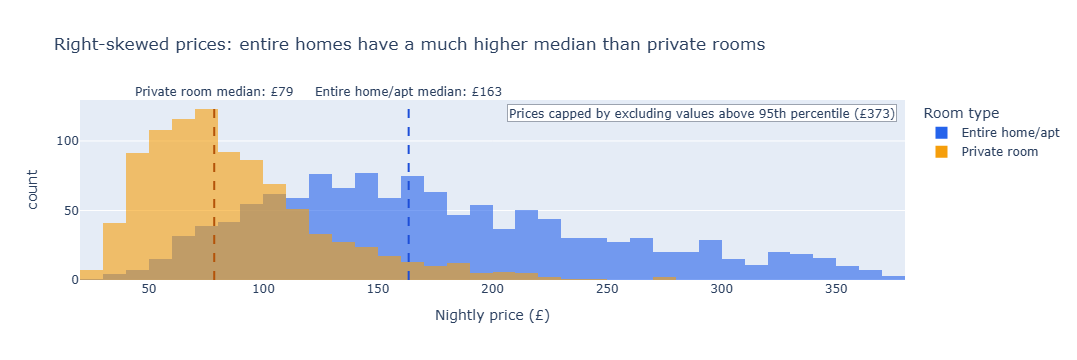

95th percentile price: £372.66
Median prices by room type (£):
room_type
Entire home/apt    163.42
Private room        78.57
Name: price, dtype: float64


In [9]:
# Task 1
# YOUR CODE HERE
# Task 1 — overlapping price distributions for Entire home/apt and Private room
# Prices above the 95th percentile are excluded as instructed.
p95 = df['price'].quantile(0.95)
df_cap = df[df['price'] <= p95].copy()
plot_df = df_cap[df_cap['room_type'].isin(['Entire home/apt', 'Private room'])].copy()

medians = plot_df.groupby('room_type')['price'].median()
fig = px.histogram(
    plot_df,
    x='price',
    color='room_type',
    barmode='overlay',
    opacity=0.6,
    nbins=40,
    color_discrete_map={
        'Entire home/apt': '#2563eb',
        'Private room': '#f59e0b'
    },
    labels={'price': 'Nightly price (£)', 'count': 'Number of listings', 'room_type': 'Room type'},
    title='Right-skewed prices: entire homes have a much higher median than private rooms'
)

# Add a differently coloured median line and annotation for each room type.
line_colours = {'Entire home/apt': '#1d4ed8', 'Private room': '#b45309'}
for room, median_price in medians.items():
    fig.add_vline(
        x=median_price,
        line_dash='dash',
        line_color=line_colours[room],
        line_width=2,
        annotation_text=f'{room} median: £{median_price:.0f}',
        annotation_position='top'
    )

fig.add_annotation(
    x=0.99, y=0.98, xref='paper', yref='paper',
    text=f'Prices capped by excluding values above 95th percentile (£{p95:.0f})',
    showarrow=False, xanchor='right', yanchor='top',
    bgcolor='white', bordercolor='#9ca3af'
)
fig.update_layout(legend_title_text='Room type')
fig.show()

print(f'95th percentile price: £{p95:.2f}')
print('Median prices by room type (£):')
print(medians.round(2))


## Task 2 — Box plot: listing activity by borough

**What to build:** A **horizontal box plot** comparing listing activity (reviews per month) across London boroughs — reviews per month is a proxy for how frequently a listing is booked.

**Requirements:**
- Horizontal orientation (borough names are long)
- Sorted by median reviews per month (most active at top)
- Highlight the **two most active** boroughs in a different colour
- Outliers shown as individual points
- Insight title naming the two busiest boroughs

> 💡 Some listings have zero reviews — these are new or inactive listings. Filter them out with before plotting

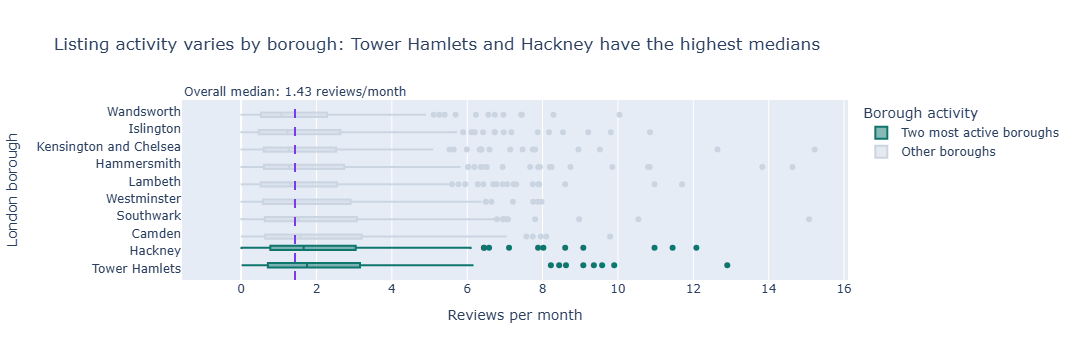

Median reviews per month by borough (descending):
neighbourhood
Tower Hamlets             1.75
Hackney                   1.66
Camden                    1.58
Southwark                 1.52
Westminster               1.39
Lambeth                   1.31
Hammersmith               1.28
Kensington and Chelsea    1.26
Islington                 1.23
Wandsworth                1.07
Name: reviews_per_month, dtype: float64

Two most active boroughs: Tower Hamlets (1.75) and Hackney (1.66) reviews/month


In [10]:
# Task 2
# YOUR CODE HERE
# Task 2 — listing activity by borough (neighbourhood)
# Exclude listings with zero reviews per month as instructed.
active_df = df[df['reviews_per_month'] > 0].copy()
borough_medians = active_df.groupby('neighbourhood')['reviews_per_month'].median().sort_values(ascending=False)
top_two = borough_medians.head(2).index.tolist()
overall_median = active_df['reviews_per_month'].median()

# Give the two most active boroughs a highlight colour; all others are neutral.
active_df['activity_group'] = np.where(
    active_df['neighbourhood'].isin(top_two),
    'Two most active boroughs',
    'Other boroughs'
)
borough_order = borough_medians.index.tolist()  # descending median activity

fig = px.box(
    active_df,
    x='reviews_per_month',
    y='neighbourhood',
    color='activity_group',
    orientation='h',
    points='outliers',
    category_orders={'neighbourhood': borough_order, 'activity_group': ['Two most active boroughs', 'Other boroughs']},
    color_discrete_map={'Two most active boroughs': '#0f766e', 'Other boroughs': '#cbd5e1'},
    labels={'reviews_per_month': 'Reviews per month', 'neighbourhood': 'London borough', 'activity_group': 'Activity'},
    title=f'Listing activity varies by borough: {top_two[0]} and {top_two[1]} have the highest medians'
)

# Put the highest-median boroughs at the top and add an overall median reference line.
fig.update_yaxes(autorange='reversed')
fig.add_vline(
    x=overall_median,
    line_dash='dash',
    line_color='#7c3aed',
    line_width=2,
    annotation_text=f'Overall median: {overall_median:.2f} reviews/month',
    annotation_position='top'
)
fig.update_layout(legend_title_text='Borough activity')
fig.show()

print('Median reviews per month by borough (descending):')
print(borough_medians.round(2))
print(f'\nTwo most active boroughs: {top_two[0]} ({borough_medians.iloc[0]:.2f}) and {top_two[1]} ({borough_medians.iloc[1]:.2f}) reviews/month')

